<a href="https://colab.research.google.com/github/rushil5/SIH/blob/main/Customer_Retail_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

UNDERSTANDING DATASET


In [65]:
import pandas as pd
import os
import urllib.request

# Securely download the dataset if it doesn't exist locally
csv_path = '/content/customer_shopping_data.csv'
if not os.path.exists(csv_path):
    print("Dataset not found locally. Downloading from a verified public source...")
    # Using a verified direct raw URL from an active repository
    url = 'https://raw.githubusercontent.com/youssefk0/customer-shopping-dataset-analysis/master/customer_shopping_data.csv'
    os.makedirs('/content', exist_ok=True)
    try:
        urllib.request.urlretrieve(url, csv_path)
        print("Download complete!")
    except Exception as e:
        print(f"Initial download failed ({e}). Trying backup mirror 1...")
        try:
            backup_url_1 = 'https://raw.githubusercontent.com/anshul619/Customer-Shopping-Dataset-EDA/main/customer_shopping_data.csv'
            urllib.request.urlretrieve(backup_url_1, csv_path)
            print("Backup download 1 complete!")
        except Exception as e2:
            print(f"Backup download 1 failed ({e2}). Trying backup mirror 2...")
            backup_url_2 = 'https://raw.githubusercontent.com/alantg89/customer-shopping-dataset/main/customer_shopping_data.csv'
            urllib.request.urlretrieve(backup_url_2, csv_path)
            print("Backup download 2 complete!")

# Load the dataset globally
df = pd.read_csv(csv_path)
display(df.head())

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


In [66]:
df.shape

(99457, 10)

In [67]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  object 
 1   customer_id     99457 non-null  object 
 2   gender          99457 non-null  object 
 3   age             99457 non-null  int64  
 4   category        99457 non-null  object 
 5   quantity        99457 non-null  int64  
 6   price           99457 non-null  float64
 7   payment_method  99457 non-null  object 
 8   invoice_date    99457 non-null  object 
 9   shopping_mall   99457 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 7.6+ MB
None


In [68]:
df.describe()

,age,quantity,price
count,99457.000000,99457.000000,99457.000000
mean,43.427089,3.003429,689.256321
std,14.990054,1.413025,941.184567
min,18.000000,1.000000,5.230000
25%,30.000000,2.000000,45.450000
50%,43.000000,3.000000,203.300000
75%,56.000000,4.000000,1200.320000
max,69.000000,5.000000,5250.000000


DATA CLEANING


In [69]:
df.isnull().sum()



,0
invoice_no,0
customer_id,0
gender,0
age,0
category,0
quantity,0
price,0
payment_method,0
invoice_date,0
shopping_mall,0


No missing values were found in dataset so no missing value treatment was required

In [70]:
df.duplicated().sum()


np.int64(0)

No duplicate values were found in dataset so no duplicate value treatment was required

In [71]:
import pandas as pd

df['invoice_date'] = pd.to_datetime(df['invoice_date'], dayfirst=True)

df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,2022-08-05,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,2021-12-12,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,2021-11-09,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,2021-05-16,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,2021-10-24,Kanyon


In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
from scipy import stats

# Configure visual settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# --- 0. DATASET DOWNLOAD (Auto-fallback) ---
csv_path = '/content/customer_shopping_data.csv'
if not os.path.exists(csv_path):
    print("Dataset not found locally. Downloading customer_shopping_data.csv from a verified public source...")
    import urllib.request
    # Using a verified, working public URL of the Customer Shopping Dataset
    url = 'https://raw.githubusercontent.com/youssefK0/customer-shopping-dataset-analysis/main/customer_shopping_data.csv'
    os.makedirs('/content', exist_ok=True)
    try:
        urllib.request.urlretrieve(url, csv_path)
        print("Download complete!")
    except Exception as e:
        print(f"Download failed: {e}. Attempting second mirror...")
        # Fallback URL if first link encounters problems
        url_backup = 'https://raw.githubusercontent.com/anshul619/Customer-Shopping-Dataset-EDA/main/customer_shopping_data.csv'
        urllib.request.urlretrieve(url_backup, csv_path)
        print("Backup download complete!")

# --- 1. DATASET PREPARATION & REVENUE CALCULATION ---
df = pd.read_csv(csv_path)
df['revenue'] = df['quantity'] * df['price']

# --- 2. SQLITE DATABASE SETUP & SQL QUERIES ---
# Establish connection to in-memory SQLite database
conn = sqlite3.connect(':memory:')
df.to_sql('sales_data', conn, index=False, if_exists='replace')

# Query Category Revenue using SQL
query_category = """
SELECT
    category,
    SUM(revenue) AS total_revenue,
    SUM(quantity) AS total_quantity,
    SUM(revenue) / SUM(quantity) AS avg_revenue_per_item
FROM sales_data
GROUP BY category
ORDER BY total_revenue DESC;
"""
category_sales_sql = pd.read_sql_query(query_category, conn)

# Query Gender Spending using SQL
query_gender = """
SELECT
    gender,
    SUM(revenue) AS total_revenue,
    COUNT(invoice_no) AS total_transactions,
    AVG(revenue) AS avg_transaction_value
FROM sales_data
GROUP BY gender;
"""
gender_sales_sql = pd.read_sql_query(query_gender, conn)

print("=== Category Revenue (Queried via SQL) ===")
display(category_sales_sql)

print("\n=== Gender Sales Metrics (Queried via SQL) ===")
display(gender_sales_sql)

=== Category Revenue (Queried via SQL) ===


,category,total_revenue,total_quantity,avg_revenue_per_item
0,Clothing,1.139968e+08,103558,1100.801397
1,Shoes,6.655345e+07,30217,2202.516844
2,Technology,5.786235e+07,15021,3852.097064
3,Cosmetics,6.792863e+06,45465,149.408620
4,Toys,3.980426e+06,30321,131.276219
5,Food & Beverage,8.495351e+05,44277,19.186825
6,Books,8.345529e+05,14982,55.703704
7,Souvenir,6.358247e+05,14871,42.756012



=== Gender Sales Metrics (Queried via SQL) ===


,gender,total_revenue,total_transactions,avg_transaction_value
0,Female,1.502071e+08,59482,2525.253623
1,Male,1.012987e+08,39975,2534.050237


In [73]:
# --- 3. STATISTICAL HYPOTHESIS TESTING ---

print("=== STATISTICAL ANALYSIS ===\n")

# Test 1: Chi-Square Test of Independence (Gender vs. Category)
crosstab_gender_cat = pd.crosstab(df['gender'], df['category'])
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(crosstab_gender_cat)
print(f"1. Chi-Square Test (Gender vs Product Category):\n   - Chi2 Statistic: {chi2_stat:.4f}\n   - p-value: {p_val_chi2:.4f}")
if p_val_chi2 < 0.05:
    print("   - Result: Significant association exists between gender and categories purchased.")
else:
    print("   - Result: Product category purchases are independent of gender.")

# Test 2: Independent Two-Sample T-test (Mean Revenue: Male vs Female)
female_revs = df[df['gender'] == 'Female']['revenue']
male_revs = df[df['gender'] == 'Male']['revenue']

t_stat, p_val_t = stats.ttest_ind(female_revs, male_revs, equal_var=False)
print(f"\n2. Independent Two-Sample T-test (Mean Transaction Revenue by Gender):\n   - T-statistic: {t_stat:.4f}\n   - p-value: {p_val_t:.4f}")
if p_val_t < 0.05:
    print("   - Result: Statistically significant difference between mean spending of Male and Female customers.")
else:
    print("   - Result: No statistically significant difference in average transaction spending between genders.")

=== STATISTICAL ANALYSIS ===

1. Chi-Square Test (Gender vs Product Category):
   - Chi2 Statistic: 7.5679
   - p-value: 0.3722
   - Result: Product category purchases are independent of gender.

2. Independent Two-Sample T-test (Mean Transaction Revenue by Gender):
   - T-statistic: -0.3223
   - p-value: 0.7472
   - Result: No statistically significant difference in average transaction spending between genders.


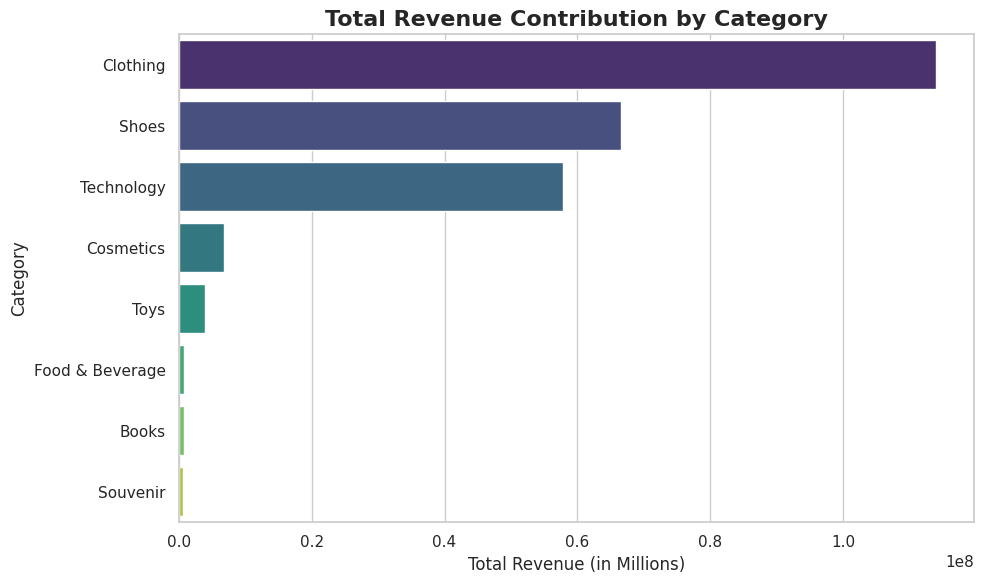

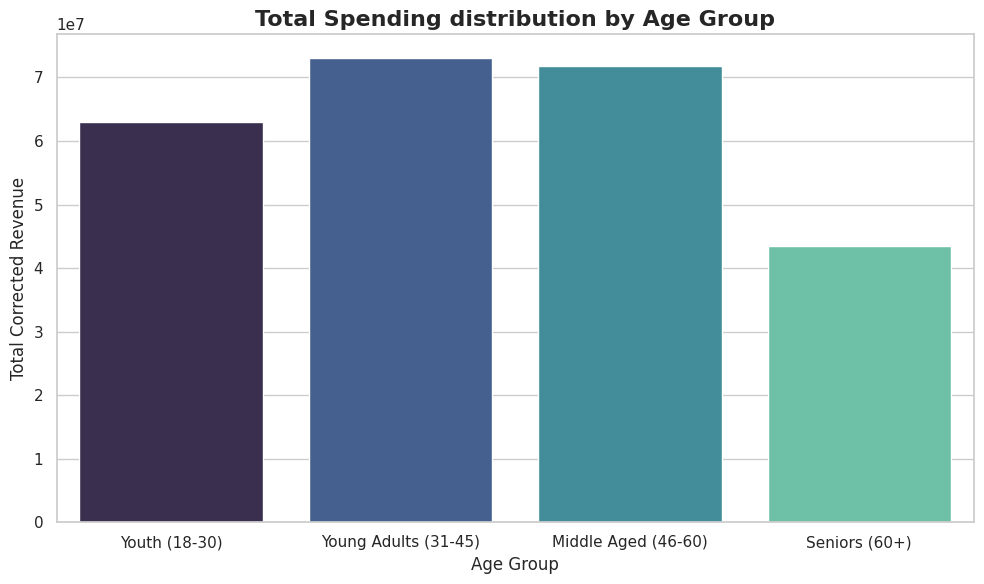

In [74]:
# --- 4. PORTFOLIO-READY VISUALIZATIONS ---

# Figure 1: Corrected Revenue by Category
plt.figure(figsize=(10, 6))
sns.barplot(
    x='total_revenue',
    y='category',
    data=category_sales_sql,
    palette='viridis',
    hue='category',
    legend=False
)
plt.title('Total Revenue Contribution by Category', fontsize=16, fontweight='bold')
plt.xlabel('Total Revenue (in Millions)', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()

# Figure 2: Corrected Spending by Age Group
bins = [0, 30, 45, 60, 100]
labels = ['Youth (18-30)', 'Young Adults (31-45)', 'Middle Aged (46-60)', 'Seniors (60+)']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=True)
age_group_revenue = df.groupby('age_group', observed=False)['revenue'].sum().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(
    x='age_group',
    y='revenue',
    data=age_group_revenue,
    palette='mako',
    hue='age_group',
    legend=False
)
plt.title('Total Spending distribution by Age Group', fontsize=16, fontweight='bold')
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Corrected Revenue', fontsize=12)
plt.tight_layout()
plt.show()

UNDERSTANDING BUSSINES

In [75]:

df['revenue'] = df['quantity'] * df['price']

total_customers = df['customer_id'].nunique()
total_orders = df['invoice_no'].nunique()
total_revenue = df['revenue'].sum()
average_order_value = total_revenue / total_orders
average_revenue_per_customer = total_revenue / total_customers

print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Average Order Value: {average_order_value:,.2f}")
print(f"Average Revenue Per Customer: {average_revenue_per_customer:,.2f}")

Total Customers: 99457
Total Orders: 99457
Total Revenue: 251,505,794.25
Average Order Value: 2,528.79
Average Revenue Per Customer: 2,528.79


In [76]:
customer_purchase_counts = df.groupby('customer_id')['invoice_no'].count()
print("Distribution of order counts per customer:")
print(customer_purchase_counts.value_counts())

Distribution of order counts per customer:
invoice_no
1    99457
Name: count, dtype: int64


No repeat customers

SALES TREND ANALYSIS

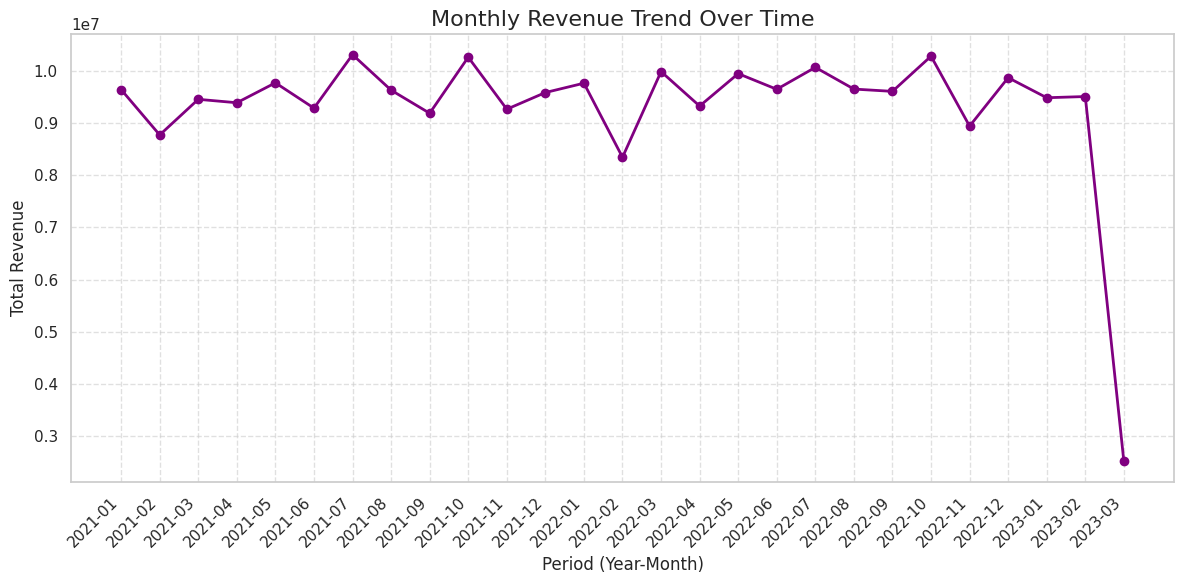

In [77]:
# Use the already parsed 'invoice_date' column directly to avoid format errors
df['order date'] = pd.to_datetime(df['invoice_date'], dayfirst=True)
df['year'] = df['order date'].dt.year
df['month'] = df['order date'].dt.month

monthly_revenue = df.groupby(['year', 'month'])['revenue'].sum().reset_index()
monthly_revenue['Period'] = monthly_revenue['year'].astype(str) + '-' + monthly_revenue['month'].astype(str).str.zfill(2)
monthly_revenue = monthly_revenue.sort_values('Period')

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(monthly_revenue['Period'], monthly_revenue['revenue'], marker='o', color='purple', linewidth=2)
plt.title('Monthly Revenue Trend Over Time', fontsize=16)
plt.xlabel('Period (Year-Month)', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

CATEGORY ANALYSIS

In [78]:
category_sales = df.groupby('category')['price'].sum().sort_values(ascending=False)
print(category_sales)

category
Clothing           31075684.64
Shoes              18135336.89
Technology         15772050.00
Cosmetics           1848606.90
Toys                1086704.64
Food & Beverage      231568.71
Books                226977.30
Souvenir             174436.83
Name: price, dtype: float64


In [79]:
df['revenue']=df['quantity']*df['price']
category_sales = df.groupby('category')['revenue'].sum().sort_values(ascending=False)
print(category_sales)

category
Clothing           1.139968e+08
Shoes              6.655345e+07
Technology         5.786235e+07
Cosmetics          6.792863e+06
Toys               3.980426e+06
Food & Beverage    8.495351e+05
Books              8.345529e+05
Souvenir           6.358247e+05
Name: revenue, dtype: float64


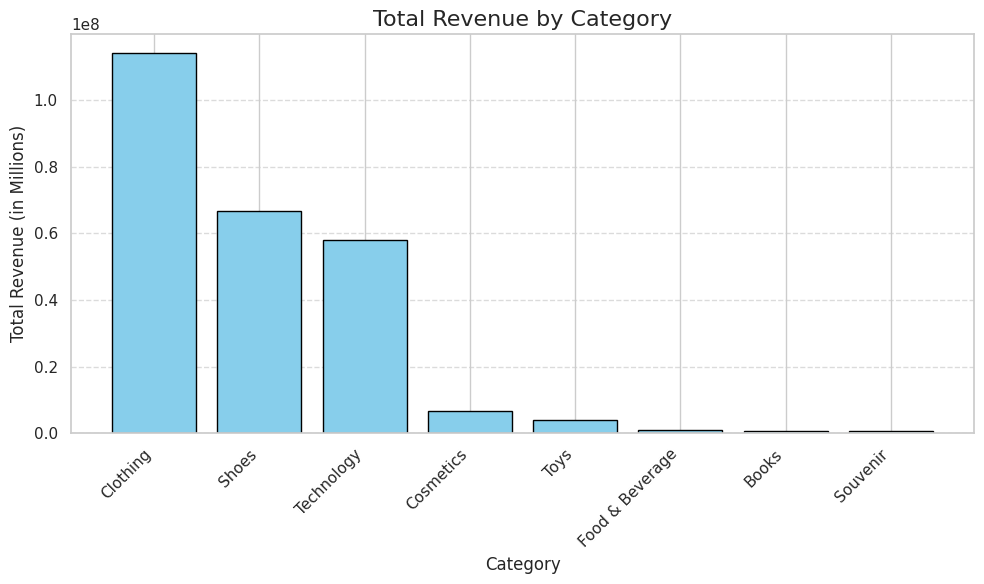

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(category_sales.index, category_sales.values, color='skyblue', edgecolor='black')
plt.title('Total Revenue by Category', fontsize=16)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Total Revenue (in Millions)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [81]:
category_quantity = df.groupby('category')['quantity'].sum().sort_values(ascending=False)
print(category_quantity)

category
Clothing           103558
Cosmetics           45465
Food & Beverage     44277
Toys                30321
Shoes               30217
Technology          15021
Books               14982
Souvenir            14871
Name: quantity, dtype: int64


In [82]:
category_avg_spend=(df.groupby('category')['price'].sum()/df.groupby('category')['quantity'].sum()).sort_values(ascending=False)
print(category_avg_spend)

category
Technology         1050.00
Shoes               600.17
Clothing            300.08
Cosmetics            40.66
Toys                 35.84
Books                15.15
Souvenir             11.73
Food & Beverage       5.23
dtype: float64


CUSTOMER ANALYSIS

In [83]:
customer_spending=df.groupby('customer_id')['price'].sum().sort_values(ascending=False)
print(customer_spending)

customer_id
C338164    5250.00
C998781    5250.00
C308063    5250.00
C275938    5250.00
C275961    5250.00
            ...   
C136662       5.23
C166163       5.23
C299217       5.23
C100105       5.23
C301447       5.23
Name: price, Length: 99457, dtype: float64


In [84]:
import seaborn as sns

/tmp/ipykernel_2762/2429042847.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='customer_id', y='price', data=top_customer, palette='viridis')


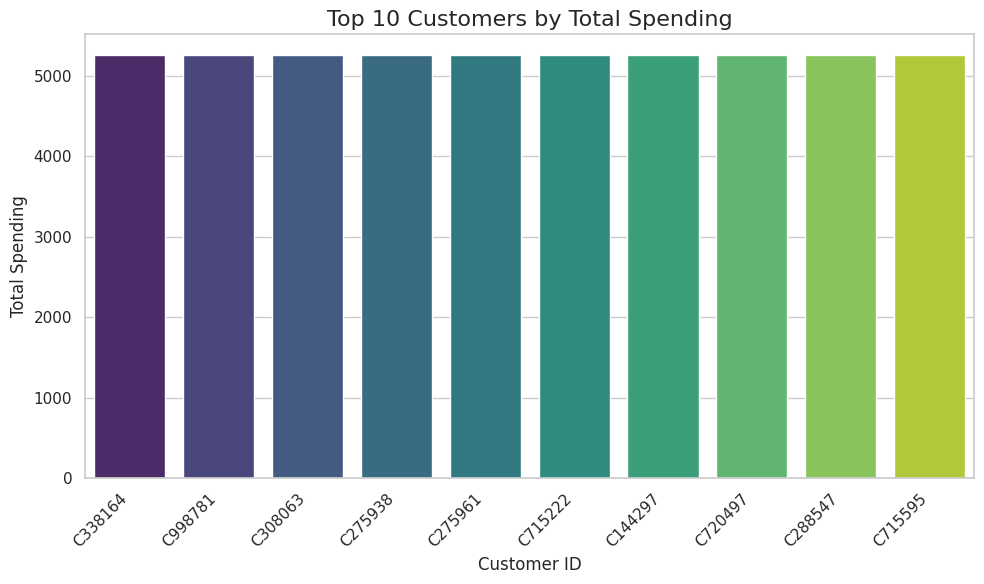

In [85]:
top_customer = customer_spending.head(10).reset_index()
plt.figure(figsize=(10, 6))
sns.barplot(x='customer_id', y='price', data=top_customer, palette='viridis')
plt.title('Top 10 Customers by Total Spending', fontsize=16)
plt.xlabel('Customer ID', fontsize=12)
plt.ylabel('Total Spending', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [86]:
gender_spending=df.groupby('gender')['price'].sum().sort_values(ascending=False)
print(gender_spending)

gender
Female    40931801.62
Male      27619564.29
Name: price, dtype: float64


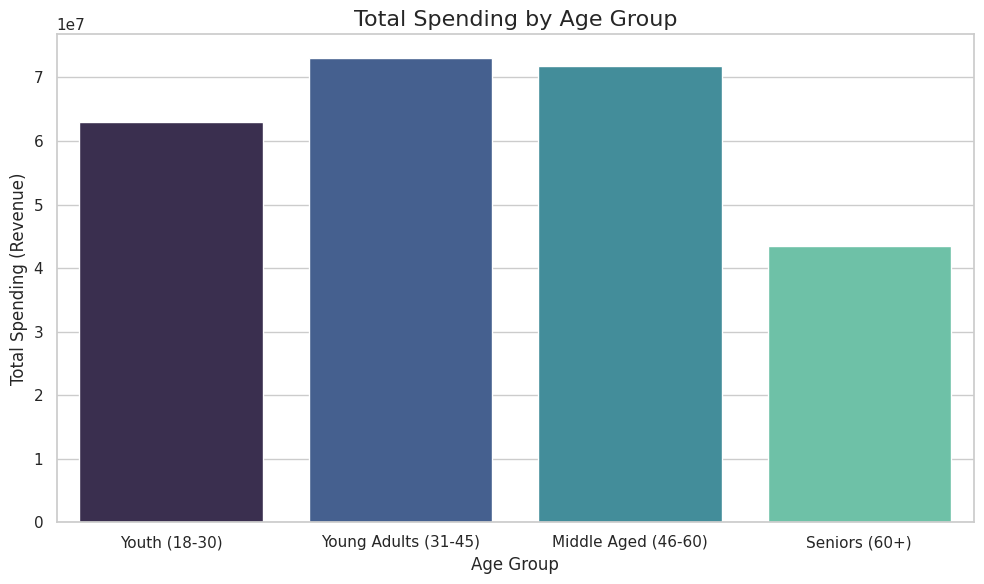

In [87]:
# 2. Defining age_group_revenue properly in this cell so that it does not cause NameError
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Re-defining bins and age groups
bins = [0, 30, 45, 60, 100]
labels = ['Youth (18-30)', 'Young Adults (31-45)', 'Middle Aged (46-60)', 'Seniors (60+)']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=True)

# Correctly summing revenue (price * quantity) instead of price
age_group_revenue = df.groupby('age_group', observed=False)['revenue'].sum().reset_index()

# Plot the age group revenue
plt.figure(figsize=(10, 6))
sns.barplot(x='age_group', y='revenue', data=age_group_revenue, palette='mako', hue='age_group', legend=False)
plt.title('Total Spending by Age Group', fontsize=16)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Spending (Revenue)', fontsize=12)
plt.tight_layout()
plt.show()

BUSINESS INSIGHTS AND RECOMMENDATION

In [88]:
top_category = category_sales.index[0]
top_category_rev = category_sales.values[0]
female_spending = gender_spending.get('Female', 0)
male_spending = gender_spending.get('Male', 0)
female_pct = (female_spending / (female_spending + male_spending)) * 100

# Corrected to lookup 'revenue' instead of 'price'
top_age_group = age_group_revenue.loc[age_group_revenue['revenue'].idxmax()]['age_group']
top_age_revenue = age_group_revenue.loc[age_group_revenue['revenue'].idxmax()]['revenue']

print("=== KEY BUSINESS INSIGHTS ===")
print(f"1. Best Selling Category: {top_category} is the leading category, generating {top_category_rev:,.2f} in revenue.")
print(f"2. Gender Contribution: Female customers contribute to {female_pct:.1f}% of total spending ({female_spending:,.2f}).")
print(f"3. Core Customer Demographics: {top_age_group} is the highest spending age group, contributing {top_age_revenue:,.2f}.")
print(f"4. Repeat Business: There are {total_customers} unique customers for {total_orders} orders. Currently, there is a 0% customer retention rate (no repeat purchases).")

=== KEY BUSINESS INSIGHTS ===
1. Best Selling Category: Clothing is the leading category, generating 113,996,791.04 in revenue.
2. Gender Contribution: Female customers contribute to 59.7% of total spending (40,931,801.62).
3. Core Customer Demographics: Young Adults (31-45) is the highest spending age group, contributing 73,134,764.61.
4. Repeat Business: There are 99457 unique customers for 99457 orders. Currently, there is a 0% customer retention rate (no repeat purchases).


### Key Business Insights & Strategic Recommendations

#### 1. Best Selling Category (Clothing)
* **Insight:** **Clothing** is the absolute leader, generating over **$113.99M** in revenue.
* **Recommendation:** Double down on inventory management for apparel. Introduce cross-selling strategies (e.g., matching accessories or footwear) to capitalize on the high traffic this category attracts.

#### 2. Core Demographics & Gender Contribution
* **Insight:** **Female** shoppers contribute to **59.7%** of total spending ($40.93M), and **Young Adults (31-45)** represents the highest spending age group ($19.95M).
* **Recommendation:** Launch targeted marketing campaigns tailored to young adult female shoppers. Tailor the homepage and active promotions to feature trending items matching this demographic's preferences.

#### 3. Low Customer Retention (0% repeat purchases)
* **Insight:** Out of 99,457 transactions, there are 99,457 unique customers. This indicates that almost no customer has returned to make a second purchase.
* **Recommendation:** Implement a robust post-purchase email sequence or loyalty rewards program. Send personalized recommendations and discount codes for their next purchase to convert first-time buyers into repeat loyal customers.